# 14 — Derive backpropagation

| | |
| --- | --- |
| **Prerequisites** | Notebooks 00–13, especially the chain rule and vector–Jacobian products (03), autograd, custom `torch.autograd.Function` and `gradcheck` (05), the softmax cross-entropy gradient $(P - Y)/N$ (10), and the from-scratch MLP trained with autograd (13) |
| **You will learn** | Backpropagation by hand for one neuron, then for a two-layer MLP in matrix form; deriving each gradient in index form and turning it into a matrix product; the shape rule ("the gradient has the shape of the thing"); why biases are summed over the batch (broadcast forward ↔ sum backward); verifying manual gradients against autograd and with `gradcheck`; backprop as a chain of vector–Jacobian products that never forms a Jacobian; what must be stored for the backward pass and how that memory scales; a tiny layer-by-layer backprop framework that trains a classifier and matches autograd; why backward costs about twice the forward pass, and finite differences cost one forward pass per parameter; where the algorithm came from |
| **Estimated time** | About 3.5 hours, plus 1–2 hours for the exercises |
| **Compute** | CPU only, under a minute. No GPU section: the networks are small, and the cost argument of Section 6 is about operation counts, which do not depend on the device. |

## Setup

In [1]:
# Setup: make the course helpers importable and record the environment.
import sys
from pathlib import Path

try:
    import dlcourse
except ImportError:  # running without `uv sync`, e.g. on Colab after cloning the repo
    root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "dlcourse").is_dir())
    sys.path.insert(0, str(root))
    import dlcourse

import matplotlib.pyplot as plt
import torch

from dlcourse import check, check_close, check_shape, passed, set_seed
from dlcourse.plotting import setup_style

setup_style()
device = dlcourse.describe_environment()
set_seed(0)

Python  3.12.13 (Darwin arm64)
PyTorch 2.14.1
CUDA available: False
MPS available:  True
Selected device: mps


In [2]:
import math
import time

import torch.nn.functional as F
from torch import nn

from dlcourse.data import make_spirals
from dlcourse.plotting import COLORS, plot_dataset, plot_decision_boundary

f64 = torch.float64

## The motivating problem

Notebook 13 built an MLP from raw tensors and trained it on spirals. The one line that did the real work was `loss.backward()`. Here is a two-layer network of that kind, on the three-class spirals:

In [3]:
X_sp, y_sp = make_spirals(n=300, classes=3, seed=0)   # X: (900, 2) float32, y: (900,) int64 in {0, 1, 2}
N_sp, D_sp, H_sp, K_sp = len(X_sp), 2, 64, 3

gen = torch.Generator().manual_seed(0)
W1 = (torch.randn(H_sp, D_sp, generator=gen) * 0.5).requires_grad_(True)   # (H, D)
b1 = torch.zeros(H_sp, requires_grad=True)                                  # (H,)
W2 = (torch.randn(K_sp, H_sp, generator=gen) * 0.1).requires_grad_(True)   # (K, H)
b2 = torch.zeros(K_sp, requires_grad=True)                                  # (K,)

loss = F.cross_entropy(torch.relu(X_sp @ W1.T + b1) @ W2.T + b2, y_sp)
loss.backward()
print(f"loss = {loss.item():.4f}   (ln 3 = {math.log(3):.4f})")
for name, p in [("W1", W1), ("b1", b1), ("W2", W2), ("b2", b2)]:
    print(f"{name}.grad: shape {tuple(p.grad.shape)}, norm {p.grad.norm().item():.4f}")

loss = 1.1027   (ln 3 = 1.0986)
W1.grad: shape (64, 2), norm 0.0245
b1.grad: shape (64,), norm 0.0397
W2.grad: shape (3, 64), norm 0.1525
b2.grad: shape (3,), norm 0.0251


Four tensors of numbers appeared, one per parameter, each the shape of its parameter. Notebook 05 told us *how* autograd produces them in general: it records the computation and runs a chain of vector–Jacobian products backwards. But what exactly is in `W1.grad`? **Can we write down every one of these numbers ourselves, as a handful of matrix products, and check that we get exactly what autograd gets?** And why does computing all of them cost only about as much as a couple of forward passes, when a finite-difference estimate (notebook 03) would need a forward pass per parameter?

That algorithm is **backpropagation**. By the end of this notebook nothing about `backward()` should feel like magic: you will have derived it, verified it, built a small framework on it, and measured its cost.

## 1. Warm-up: one neuron, one example

Start with the smallest network that has all the ingredients: one input $x$, one hidden ReLU unit, one linear output, and a squared-error loss against a target $t$:

$$a = wx + b, \qquad h = \operatorname{relu}(a), \qquad z = vh + c, \qquad L = \tfrac12 (z - t)^2.$$

Parameters: $w, b$ (hidden unit) and $v, c$ (output). Take $x = 1.5$, $t = 1$, $w = 2$, $b = -1$, $v = -0.5$, $c = 0.5$.

**Forward pass** (keep every intermediate value):

$$a = 2 \cdot 1.5 - 1 = 2, \qquad h = \operatorname{relu}(2) = 2, \qquad z = -0.5 \cdot 2 + 0.5 = -0.5, \qquad L = \tfrac12(-0.5 - 1)^2 = 1.125.$$

**Local derivatives.** Each step is a simple function of its inputs, with simple partial derivatives:

| step | partial derivatives |
| --- | --- |
| $L = \frac12(z - t)^2$ | $\partial L/\partial z = z - t$ |
| $z = vh + c$ | $\partial z/\partial v = h$, $\ \partial z/\partial c = 1$, $\ \partial z/\partial h = v$ |
| $h = \operatorname{relu}(a)$ | $\partial h/\partial a = 1$ if $a > 0$, else $0$ (the convention at $a = 0$, notebook 03) |
| $a = wx + b$ | $\partial a/\partial w = x$, $\ \partial a/\partial b = 1$, $\ \partial a/\partial x = w$ |

**Backward pass.** Walk from the loss towards the inputs. By the chain rule, the derivative of $L$ with respect to any quantity is the derivative with respect to the next quantity downstream, times one local derivative:

$$\frac{\partial L}{\partial z} = z - t = -1.5, \qquad \frac{\partial L}{\partial v} = \frac{\partial L}{\partial z}\, h = -3, \qquad \frac{\partial L}{\partial c} = \frac{\partial L}{\partial z} = -1.5,$$

$$\frac{\partial L}{\partial h} = \frac{\partial L}{\partial z}\, v = 0.75, \qquad \frac{\partial L}{\partial a} = \frac{\partial L}{\partial h}\cdot 1 = 0.75, \qquad \frac{\partial L}{\partial w} = \frac{\partial L}{\partial a}\, x = 1.125, \qquad \frac{\partial L}{\partial b} = \frac{\partial L}{\partial a} = 0.75.$$

In [4]:
x_n, t_n = 1.5, 1.0
w_n, b_n, v_n, c_n = 2.0, -1.0, -0.5, 0.5

# forward: compute and keep every intermediate value
a_n = w_n * x_n + b_n
h_n = max(a_n, 0.0)
z_n = v_n * h_n + c_n
L_n = 0.5 * (z_n - t_n) ** 2

# backward: one local derivative per step, from the loss towards the inputs
dz = z_n - t_n
dv, dc, dh = dz * h_n, dz, dz * v_n
da = dh * (1.0 if a_n > 0 else 0.0)
dw, db = da * x_n, da
print(f"forward:  a = {a_n}, h = {h_n}, z = {z_n}, L = {L_n}")
print(f"backward: dL/dz = {dz}, dL/dv = {dv}, dL/dc = {dc}, dL/dh = {dh}, dL/da = {da}, dL/dw = {dw}, dL/db = {db}")

# the same with autograd
pw, pb, pv, pc = (torch.tensor(val, dtype=f64, requires_grad=True) for val in (w_n, b_n, v_n, c_n))
L_t = 0.5 * (pv * torch.relu(pw * x_n + pb) + pc - t_n) ** 2
L_t.backward()
print(f"autograd: dL/dv = {pv.grad.item()}, dL/dc = {pc.grad.item()}, dL/dw = {pw.grad.item()}, dL/db = {pb.grad.item()}")

forward:  a = 2.0, h = 2.0, z = -0.5, L = 1.125
backward: dL/dz = -1.5, dL/dv = -3.0, dL/dc = -1.5, dL/dh = 0.75, dL/da = 0.75, dL/dw = 1.125, dL/db = 0.75
autograd: dL/dv = -3.0, dL/dc = -1.5, dL/dw = 1.125, dL/db = 0.75


Every number matches. Two patterns are worth naming, because they are all of backpropagation in miniature:

1. **A parameter's gradient is (upstream gradient) × (what the parameter multiplied in the forward pass).** $\partial L/\partial v = \frac{\partial L}{\partial z}\cdot h$ and $\partial L/\partial w = \frac{\partial L}{\partial a}\cdot x$. A bias multiplies the constant 1, so its gradient *is* the upstream gradient.
2. **The gradient flows backwards through the same weights the signal flowed forwards through.** $\partial L/\partial h = \frac{\partial L}{\partial z}\cdot v$: the forward pass multiplied $h$ by $v$, so the backward pass multiplies the gradient by $v$. A nonlinearity multiplies it by its local slope — for ReLU, 1 or 0.

And the backward pass needed the forward values $x$, $h$, $v$, $a$ (only its sign) and $z$: they had to be **stored** during the forward pass. Section 4 comes back to what that costs.

### Checkpoint 1.1

Same neuron, same $x$, $t$, $w$, $v$, $c$, but now $b = -4$. By hand first, then as plain Python floats (no autograd): the forward values, then `dv_dead`, `dc_dead`, `dw_dead`, `db_dead` $= \partial L/\partial v, \partial L/\partial c, \partial L/\partial w, \partial L/\partial b$. Which parameters receive no gradient at all, and why?

<details>
<summary><b>💡 Hint</b></summary>

Now $a = 3 - 4 = -1 < 0$, so $h = 0$ and $z = c$. The ReLU's local derivative is 0, so everything upstream of it (in the backward direction: $a$, $w$, $b$) gets 0. And $\partial L/\partial v = \frac{\partial L}{\partial z}\, h$ with $h = 0$.

</details>

In [ ]:
b_dead = -4.0
# YOUR CODE HERE
raise NotImplementedError
print(dv_dead, dc_dead, dw_dead, db_dead)

In [ ]:
_g = [dv_dead, dc_dead, dw_dead, db_dead]
_p = [torch.tensor(val, dtype=f64, requires_grad=True) for val in (v_n, c_n, w_n, b_dead)]
(0.5 * (_p[0] * torch.relu(_p[2] * x_n + _p[3]) + _p[1] - t_n) ** 2).backward()
for _name, _mine, _q in zip(["dv_dead", "dc_dead", "dw_dead", "db_dead"], _g, _p):
    check_close(_mine, _q.grad.item(), _name)
passed("Checkpoint 1.1")

Only $c$ learns. The hidden unit is switched off for this input ($a < 0$), so it contributes nothing to $z$, and nothing about $v$, $w$ or $b$ would change $L$ by an infinitesimal nudge. If a ReLU unit is off for *every* training example, it never receives a gradient again — a "dead" unit, which notebook 16 measures.

## 2. A two-layer MLP in matrix form

Now the network of the motivating problem, for a whole batch at once. Notation (one example per **row**, as throughout the course):

| quantity | definition | shape |
| --- | --- | --- |
| inputs | $X$ | $(N, D)$ |
| hidden pre-activations | $A_1 = X W_1^\top + \mathbf b_1$ | $(N, H)$ |
| hidden activations | $H_1 = \operatorname{relu}(A_1)$ | $(N, H)$ |
| logits | $Z = H_1 W_2^\top + \mathbf b_2$ | $(N, K)$ |
| loss | $L = \frac1N\sum_i -\log \operatorname{softmax}(Z_{i,:})_{y_i}$ | scalar |

with $W_1$ of shape $(H, D)$, $\mathbf b_1$ of shape $(H,)$, $W_2$ of shape $(K, H)$, $\mathbf b_2$ of shape $(K,)$ — `nn.Linear`'s `(out, in)` layout.

For any tensor $T$ in this computation, write $G_T = \partial L/\partial T$: a tensor **of the same shape as $T$** whose entry $(i, j)$ says how fast $L$ changes when $T_{ij}$ alone is nudged. ($G_T$ is the $\bar T$ of notebook 05.) The **forward pass** computes and stores the intermediates — the **cache** — and the **backward pass** computes $G_Z$, then the gradients of everything that feeds into $Z$, and so on back to the first layer.

In [7]:
def init_params(D, H, K, gen, dtype=torch.float32):
    """Two-layer MLP parameters, initialized like nn.Linear's default (notebook 18 explains this choice)."""
    def uniform(*shape, fan_in):
        return (2 * torch.rand(*shape, generator=gen, dtype=dtype) - 1) / math.sqrt(fan_in)
    return {"W1": uniform(H, D, fan_in=D), "b1": uniform(H, fan_in=D),
            "W2": uniform(K, H, fan_in=H), "b2": uniform(K, fan_in=H)}


def mlp_forward(params, X):
    """Forward pass. X: (N, D) -> logits Z: (N, K), plus the cache the backward pass needs."""
    A1 = X @ params["W1"].T + params["b1"]     # (N, H)
    H1 = torch.relu(A1)                        # (N, H)
    Z = H1 @ params["W2"].T + params["b2"]     # (N, K)
    return Z, {"X": X, "A1": A1, "H1": H1}


# A small batch to look at: N = 5 spiral points, H = 4 hidden units, in float64
X_s = X_sp[[0, 300, 600, 150, 750]].double()                      # (5, 2), one point from each arm, then two more
y_s = y_sp[[0, 300, 600, 150, 750]]                               # (5,)
params_s = init_params(2, 4, 3, torch.Generator().manual_seed(1), dtype=f64)
Z_s, cache_s = mlp_forward(params_s, X_s)
for name, T in [*cache_s.items(), ("Z", Z_s)]:
    print(f"{name:3s} shape {tuple(T.shape)}")

X   shape (5, 2)
A1  shape (5, 4)
H1  shape (5, 4)
Z   shape (5, 3)


### Step 1: the logits

Notebook 10 (Section 6) derived the gradient of the mean cross-entropy with respect to the logits. With $P = \operatorname{softmax}(Z)$ row by row and $Y$ the one-hot labels, both $(N, K)$:

$$G_Z = \frac{\partial L}{\partial Z} = \frac1N (P - Y).$$

The $\frac1N$ comes from the **mean** over the batch: example $i$'s loss enters $L$ with weight $\frac1N$. Row $i$ of $G_Z$ depends only on example $i$.

In [8]:
P_s = torch.softmax(Z_s, dim=1)                       # (N, K)
Y_s = F.one_hot(y_s, 3).to(f64)                       # (N, K)
G_Z = (P_s - Y_s) / len(X_s)                          # (N, K)
print("G_Z =\n", G_Z.numpy().round(4))
print("row sums:", G_Z.sum(dim=1).numpy().round(15))

G_Z =
 [[-0.1167  0.0446  0.0722]
 [ 0.0982 -0.152   0.0538]
 [ 0.0981  0.0501 -0.1482]
 [-0.1005  0.0499  0.0507]
 [ 0.0821  0.041  -0.1231]]
row sums: [ 0.  0. -0.  0. -0.]


Each row sums to zero (notebook 10: the correct class is pushed up by exactly as much as the others are pushed down, in total).

### Step 2: the output weights $W_2$ — index form first

Write the second layer one entry at a time:

$$Z_{ik} = \sum_{j=1}^{H} (H_1)_{ij}\,(W_2)_{kj} + (b_2)_k.$$

Which logits does the single weight $(W_2)_{kj}$ affect? Every $Z_{ik}$ with that same $k$ — one per example $i$ — and no others. By the multivariable chain rule (notebook 03: when a quantity influences $L$ through several intermediate values, its derivative is the **sum** over those paths):

$$\frac{\partial L}{\partial (W_2)_{kj}} = \sum_{i=1}^{N} \frac{\partial L}{\partial Z_{ik}}\,\frac{\partial Z_{ik}}{\partial (W_2)_{kj}} = \sum_{i=1}^{N} (G_Z)_{ik}\,(H_1)_{ij}.$$

**Now read it as a matrix product.** $\sum_i (G_Z)_{ik} (H_1)_{ij}$ is entry $(k, j)$ of $G_Z^\top H_1$ (the sum runs over the shared index $i$, which must be the inner dimension). So

$$\nabla_{W_2} L = G_Z^\top H_1 \qquad (K, N) \times (N, H) = (K, H).$$

This is pattern 1 of Section 1 summed over the batch: (upstream gradient) × (what $W_2$ multiplied), one term per example.

**The shape rule.** The gradient of $L$ with respect to a tensor has the shape of that tensor — "the gradient has the shape of the thing". $\nabla_{W_2} L$ must be $(K, H)$, and the ingredients are $G_Z$ $(N, K)$ and $H_1$ $(N, H)$. There is only one way to multiply them into a $(K, H)$ matrix: $G_Z^\top H_1$. This makes the shape rule an excellent way to *remember* (or re-derive) the formula, and to catch mistakes — with one blind spot, shown at the end of this section.

In [9]:
dW2 = G_Z.T @ cache_s["H1"]                          # (K, H)
# the index form, as an explicit triple loop, for comparison
dW2_loop = torch.zeros(3, 4, dtype=f64)
for k in range(3):
    for j in range(4):
        dW2_loop[k, j] = sum(G_Z[i, k] * cache_s["H1"][i, j] for i in range(len(X_s)))
print("dW2 shape:", tuple(dW2.shape), "  W2 shape:", tuple(params_s["W2"].shape))
print("max |matrix form - index form| =", (dW2 - dW2_loop).abs().max().item())

dW2 shape: (3, 4)   W2 shape: (3, 4)
max |matrix form - index form| = 6.938893903907228e-18


### Step 3: the output bias — broadcasting forward, summing backward

$(b_2)_k$ appears in $Z_{ik}$ for every example $i$, with $\partial Z_{ik}/\partial (b_2)_k = 1$. So

$$\frac{\partial L}{\partial (b_2)_k} = \sum_{i=1}^N (G_Z)_{ik}, \qquad \nabla_{\mathbf b_2} L = \text{column sums of } G_Z \qquad (K,).$$

Why a **sum** over the batch? In the forward pass, `H1 @ W2.T + b2` **broadcasts** $\mathbf b_2$ (shape $(K,)$) to shape $(N, K)$: it is used $N$ times, once per row. A quantity used in $N$ places collects the gradient from all $N$ of them. This is a general rule:

> **Broadcasting in the forward pass ↔ summation in the backward pass.** If a tensor of shape $s$ is broadcast to shape $S$, its gradient is the upstream gradient (shape $S$) summed over the broadcast dimensions, back down to shape $s$.

And the dual: a **sum** (or mean) in the forward pass becomes a **broadcast** (copy) in the backward pass — which is why the mean in the loss puts the same factor $\frac1N$ on every row of $G_Z$.

PyTorch has exactly this reduction as a method, `G.sum_to_size(shape)`. We check the rule on an elementwise layer $Y = X \odot \mathbf s$ with a scale $\mathbf s$ broadcast from several shapes, against autograd:

In [10]:
X_b = torch.randn(4, 3, dtype=f64, generator=torch.Generator().manual_seed(2))     # (N, D) = (4, 3)
G_b = torch.randn(4, 3, dtype=f64, generator=torch.Generator().manual_seed(3))     # an arbitrary upstream gradient
for s_shape in [(3,), (1, 3), (4, 1), ()]:
    s = torch.randn(s_shape, dtype=f64, requires_grad=True)
    Y_b = X_b * s                                                    # broadcast to (4, 3)
    (g_auto,) = torch.autograd.grad(Y_b, s, grad_outputs=G_b)        # VJP with upstream gradient G_b
    g_rule = (G_b * X_b).sum_to_size(s_shape)                        # local derivative X, then sum over broadcast dims
    print(f"s of shape {str(s_shape):7s}: gradient shape {str(tuple(g_auto.shape)):7s}  "
          f"max |rule - autograd| = {(g_rule - g_auto).abs().max().item():.1e}")

s of shape (3,)   : gradient shape (3,)     max |rule - autograd| = 0.0e+00
s of shape (1, 3) : gradient shape (1, 3)   max |rule - autograd| = 0.0e+00
s of shape (4, 1) : gradient shape (4, 1)   max |rule - autograd| = 0.0e+00
s of shape ()     : gradient shape ()       max |rule - autograd| = 0.0e+00


For every shape, the gradient has the shape of $\mathbf s$, and it is the elementwise gradient $G \odot X$ summed over exactly the dimensions along which $\mathbf s$ was broadcast: rows for `(3,)` and `(1, 3)`, columns for `(4, 1)`, everything for a scalar.

In [11]:
db2 = G_Z.sum(dim=0)                                  # (K,)
print("db2 =", db2.numpy().round(5), "  shape", tuple(db2.shape))

db2 = [ 0.06114  0.03353 -0.09467]   shape (3,)


### Step 4: back through the weights — the hidden activations

Which logits does $(H_1)_{ij}$ affect? $Z_{ik}$ for every class $k$, but only for its own example $i$ (examples do not interact in an MLP). Summing over those paths:

$$\frac{\partial L}{\partial (H_1)_{ij}} = \sum_{k=1}^{K} (G_Z)_{ik}\,\frac{\partial Z_{ik}}{\partial (H_1)_{ij}} = \sum_{k=1}^{K} (G_Z)_{ik}\,(W_2)_{kj} = (G_Z W_2)_{ij},$$

$$G_{H_1} = G_Z W_2 \qquad (N, K) \times (K, H) = (N, H).$$

This is pattern 2: the forward pass multiplied by $W_2^\top$ on the right, the backward pass multiplies by $W_2$. The shape rule again leaves only one option.

In [12]:
G_H1 = G_Z @ params_s["W2"]                          # (N, H)
print("G_H1 shape:", tuple(G_H1.shape), "  H1 shape:", tuple(cache_s["H1"].shape))

G_H1 shape: (5, 4)   H1 shape: (5, 4)


### Step 5: through the ReLU

$(H_1)_{ij} = \operatorname{relu}((A_1)_{ij})$ depends only on $(A_1)_{ij}$, so there is a single path and no sum:

$$(G_{A_1})_{ij} = (G_{H_1})_{ij}\,\operatorname{relu}'((A_1)_{ij}), \qquad G_{A_1} = G_{H_1} \odot \mathbb 1[A_1 > 0],$$

where $\odot$ is the elementwise product and $\mathbb 1[A_1 > 0]$ is the $(N, H)$ **mask** of units that were on. (In Jacobian language, notebook 03: an elementwise function has a diagonal Jacobian, and multiplying by a diagonal matrix is an elementwise product.) The gradient passes unchanged through units that were on and is blocked by units that were off.

In [13]:
mask = cache_s["A1"] > 0                             # (N, H) bool
G_A1 = G_H1 * mask                                   # (N, H)
print("mask (1 = unit on):\n", mask.int().numpy())
print("G_A1 =\n", G_A1.numpy().round(5))

mask (1 = unit on):
 [[1 1 1 0]
 [1 1 0 0]
 [0 0 1 0]
 [0 0 0 0]
 [1 1 1 0]]
G_A1 =
 [[ 0.01144  0.03602  0.07677  0.     ]
 [ 0.02296  0.0616  -0.      -0.     ]
 [-0.      -0.      -0.09781 -0.     ]
 [ 0.       0.       0.       0.     ]
 [-0.02863 -0.0834  -0.08148 -0.     ]]


Exactly the entries where the mask is 0 are zero in $G_{A_1}$.

### Step 6: the first layer

$A_1 = X W_1^\top + \mathbf b_1$ has the same form as $Z = H_1 W_2^\top + \mathbf b_2$, with $X$ in place of $H_1$ and $G_{A_1}$ in place of $G_Z$. So steps 2–4 apply unchanged:

$$\nabla_{W_1} L = G_{A_1}^\top X \quad (H, D), \qquad \nabla_{\mathbf b_1} L = \sum_i (G_{A_1})_{i,:} \quad (H,), \qquad G_X = G_{A_1} W_1 \quad (N, D).$$

$G_X$ is not needed for training — $X$ is data, not a parameter — so a training backward pass skips it (Section 6 counts the saving). We compute it here because Section 3 checks it too.

In [14]:
dW1 = G_A1.T @ cache_s["X"]                          # (H, D)
db1 = G_A1.sum(dim=0)                                # (H,)
G_X = G_A1 @ params_s["W1"]                          # (N, D)
for name, g, p in [("dW1", dW1, params_s["W1"]), ("db1", db1, params_s["b1"]), ("dW2", dW2, params_s["W2"]), ("db2", db2, params_s["b2"])]:
    print(f"{name}: shape {tuple(g.shape)}  (parameter shape {tuple(p.shape)})")

dW1: shape (4, 2)  (parameter shape (4, 2))
db1: shape (4,)  (parameter shape (4,))
dW2: shape (3, 4)  (parameter shape (3, 4))
db2: shape (3,)  (parameter shape (3,))


### The whole backward pass

Collected in order, with the shape of every result:

| step | formula | shape |
| --- | --- | --- |
| loss → logits | $G_Z = (P - Y)/N$ | $(N, K)$ |
| output weights | $\nabla_{W_2} L = G_Z^\top H_1$ | $(K, H)$ |
| output bias | $\nabla_{\mathbf b_2} L = \sum_i (G_Z)_{i,:}$ | $(K,)$ |
| back through $W_2$ | $G_{H_1} = G_Z W_2$ | $(N, H)$ |
| back through ReLU | $G_{A_1} = G_{H_1} \odot \mathbb 1[A_1 > 0]$ | $(N, H)$ |
| hidden weights | $\nabla_{W_1} L = G_{A_1}^\top X$ | $(H, D)$ |
| hidden bias | $\nabla_{\mathbf b_1} L = \sum_i (G_{A_1})_{i,:}$ | $(H,)$ |

Seven lines, all matrix products, elementwise products and sums. As a function:

In [15]:
def mlp_backward(params, cache, Z, y):
    """Manual backward pass of the two-layer MLP with mean cross-entropy.
    Returns the gradients of the parameters, plus the intermediate gradients for inspection."""
    N, K = Z.shape
    G_Z = (torch.softmax(Z, dim=1) - F.one_hot(y, K).to(Z.dtype)) / N   # (N, K)
    dW2 = G_Z.T @ cache["H1"]                                          # (K, H)
    db2 = G_Z.sum(dim=0)                                               # (K,)
    G_H1 = G_Z @ params["W2"]                                          # (N, H)
    G_A1 = G_H1 * (cache["A1"] > 0)                                    # (N, H)
    dW1 = G_A1.T @ cache["X"]                                          # (H, D)
    db1 = G_A1.sum(dim=0)                                              # (H,)
    return {"W1": dW1, "b1": db1, "W2": dW2, "b2": db2,
            "G_Z": G_Z, "G_H1": G_H1, "G_A1": G_A1, "G_X": G_A1 @ params["W1"]}

### The blind spot of the shape rule

The shape rule cannot tell $G^\top H$ from $H^\top G$ when both have the same shape — which happens when a layer is **square** (as many outputs as inputs). For a square layer $W$ of shape $(H, H)$, the wrong formula $H_{\text{in}}^\top G$ computes $(\nabla_W L)^\top$, the transpose of the correct gradient, with the right shape:

In [16]:
gen_sq = torch.Generator().manual_seed(4)
H_in = torch.randn(6, 4, dtype=f64, generator=gen_sq)                       # (N, H) input to a square layer
W_sq = torch.randn(4, 4, dtype=f64, generator=gen_sq, requires_grad=True)   # (H, H)
G_out = torch.randn(6, 4, dtype=f64, generator=gen_sq)                      # upstream gradient (N, H)
(g_true,) = torch.autograd.grad(H_in @ W_sq.T, W_sq, grad_outputs=G_out)
right, wrong = G_out.T @ H_in, H_in.T @ G_out
print("shapes:", tuple(right.shape), tuple(wrong.shape))
print(f"max |G^T H - autograd| = {(right - g_true).abs().max().item():.1e}")
print(f"max |H^T G - autograd| = {(wrong - g_true).abs().max().item():.2f}   (it equals the transpose: "
      f"{torch.allclose(wrong, g_true.T)})")

shapes: (4, 4) (4, 4)
max |G^T H - autograd| = 0.0e+00
max |H^T G - autograd| = 6.69   (it equals the transpose: True)


Both run without an error; one is wrong. Shapes are necessary, not sufficient — which is why Section 3 compares every gradient with an independent computation.

### Checkpoint 2.1

A two-layer MLP has $D = 10$ inputs, $H = 32$ hidden units, $K = 5$ classes, and a batch of $N = 64$. Without running anything, fill in the shapes (as tuples) of: `shape_GZ` $= G_Z$, `shape_dW2`, `shape_GH1`, `shape_dW1`, `shape_db1`, `shape_GX`.

<details>
<summary><b>💡 Hint</b></summary>

Every gradient has the shape of the tensor it is the gradient of: $Z$ is $(N, K)$, $W_2$ is $(K, H)$, $H_1$ is $(N, H)$, $W_1$ is $(H, D)$, $\mathbf b_1$ is $(H,)$, $X$ is $(N, D)$.

</details>

In [ ]:
# YOUR CODE HERE
raise NotImplementedError

In [ ]:
_shapes = [shape_GZ, shape_dW2, shape_GH1, shape_dW1, shape_db1, shape_GX]
_p = init_params(10, 32, 5, torch.Generator().manual_seed(0))
_X, _y = torch.randn(64, 10), torch.randint(0, 5, (64,))
_Z, _c = mlp_forward(_p, _X)
_g = mlp_backward(_p, _c, _Z, _y)
for _name, _mine, _key in zip(["shape_GZ", "shape_dW2", "shape_GH1", "shape_dW1", "shape_db1", "shape_GX"], _shapes,
                              ["G_Z", "W2", "G_H1", "W1", "b1", "G_X"]):
    check(tuple(_mine) == tuple(_g[_key].shape), f"{_name} = {tuple(_mine)}, expected {tuple(_g[_key].shape)}")
passed("Checkpoint 2.1")

### Checkpoint 2.2

A **per-feature scale-and-shift** layer computes $Y = X \odot \mathbf s + \mathbf t$ with $X$ of shape $(N, D)$ and $\mathbf s$, $\mathbf t$ of shape $(D,)$, broadcast over the batch. Given the upstream gradient `G_y` (shape $(N, D)$), compute `ds` and `dt` (shape $(D,)$ each) and the downstream gradient `dX` (shape $(N, D)$) — no autograd.

<details>
<summary><b>💡 Hint</b></summary>

Elementwise: $\partial Y_{id}/\partial s_d = X_{id}$, $\partial Y_{id}/\partial t_d = 1$, $\partial Y_{id}/\partial X_{id} = s_d$. Then sum over the dimension along which $\mathbf s$ and $\mathbf t$ were broadcast (the batch, `dim=0`). $X$ was not broadcast, so `dX` needs no sum.

</details>

In [ ]:
gen_c = torch.Generator().manual_seed(5)
X_c = torch.randn(8, 3, dtype=f64, generator=gen_c)
s_c, t_c = torch.randn(3, dtype=f64, generator=gen_c), torch.randn(3, dtype=f64, generator=gen_c)
G_y = torch.randn(8, 3, dtype=f64, generator=gen_c)
# YOUR CODE HERE
raise NotImplementedError

In [ ]:
check_shape(ds, (3,), "ds")
check_shape(dt, (3,), "dt")
check_shape(dX, (8, 3), "dX")
_X = X_c.clone().requires_grad_(True)
_s, _t = s_c.clone().requires_grad_(True), t_c.clone().requires_grad_(True)
_gX, _gs, _gt = torch.autograd.grad(_X * _s + _t, (_X, _s, _t), grad_outputs=G_y)
check_close(ds, _gs, "ds")
check_close(dt, _gt, "dt")
check_close(dX, _gX, "dX")
passed("Checkpoint 2.2")

## 3. Verify: autograd and `gradcheck`

A derivation is a claim; now test it. First, on the full spiral dataset ($N = 900$, $H = 64$) in `float64`, compare every gradient of `mlp_backward` — the parameter gradients and the intermediate ones — with autograd. To read autograd's gradients of intermediate tensors we call `retain_grad()` on them (notebook 05).

In [21]:
X64, y64 = X_sp.double(), y_sp                                      # (900, 2) float64, (900,)
params64 = init_params(2, 64, 3, torch.Generator().manual_seed(0), dtype=f64)

# manual
Z64, cache64 = mlp_forward(params64, X64)
manual = mlp_backward(params64, cache64, Z64, y64)

# autograd, on copies of the same parameters and input
leaves = {k: v.clone().requires_grad_(True) for k, v in params64.items()}
X_leaf = X64.clone().requires_grad_(True)
Z_a, cache_a = mlp_forward(leaves, X_leaf)
for T in (Z_a, cache_a["A1"], cache_a["H1"]):
    T.retain_grad()
F.cross_entropy(Z_a, y64).backward()
autograd_grads = {"W1": leaves["W1"].grad, "b1": leaves["b1"].grad, "W2": leaves["W2"].grad, "b2": leaves["b2"].grad,
                  "G_Z": Z_a.grad, "G_H1": cache_a["H1"].grad, "G_A1": cache_a["A1"].grad, "G_X": X_leaf.grad}

print(f"{'gradient':8s} {'shape':>10s}  {'max |manual - autograd|':>24s}  {'max |autograd|':>15s}")
for name, g in manual.items():
    diff = (g - autograd_grads[name]).abs().max().item()
    print(f"{name:8s} {str(tuple(g.shape)):>10s}  {diff:24.1e}  {autograd_grads[name].abs().max().item():15.2e}")
    check_close(g, autograd_grads[name], name, rtol=1e-10, atol=1e-14)
passed("Every manual gradient matches autograd")

gradient      shape   max |manual - autograd|   max |autograd|
W1          (64, 2)                   1.7e-18         7.21e-03
b1            (64,)                   1.0e-17         1.47e-02
W2          (3, 64)                   3.8e-17         7.00e-02
b2             (3,)                   6.9e-18         7.49e-02
G_Z        (900, 3)                   2.2e-19         8.67e-04
G_H1      (900, 64)                   5.4e-20         1.79e-04
G_A1      (900, 64)                   5.4e-20         1.79e-04
G_X        (900, 2)                   1.4e-19         3.22e-04
✅ Every manual gradient matches autograd passed


All eight gradients agree with autograd to between about $10^{-20}$ and $4 \times 10^{-17}$: in every case some $10^{14}$ to $10^{16}$ times smaller than the gradient entries themselves, which is `float64` rounding.

This is strong evidence, but autograd is not an independent oracle in every sense: if our *forward* pass had a mistake, both would differentiate the same wrong function. `gradcheck` (notebook 05) uses finite differences of the forward pass instead, so it tests the backward against the function itself. To use it, wrap the manual forward and backward in a custom `torch.autograd.Function`. Its `forward` returns the scalar loss; its `backward` receives the upstream gradient $\bar L$ (a scalar, 1 in an ordinary `loss.backward()`) and must return $\bar L$ times the gradient for each input, and `None` for the integer labels.

In [22]:
class MLPCrossEntropy(torch.autograd.Function):
    """Mean cross-entropy of a two-layer ReLU MLP, with the hand-derived backward pass."""

    @staticmethod
    def forward(ctx, X, W1, b1, W2, b2, y):
        params = {"W1": W1, "b1": b1, "W2": W2, "b2": b2}
        Z, cache = mlp_forward(params, X)
        ctx.save_for_backward(X, cache["A1"], cache["H1"], Z, W1, W2, y)
        return F.cross_entropy(Z, y)

    @staticmethod
    def backward(ctx, grad_L):
        X, A1, H1, Z, W1, W2, y = ctx.saved_tensors
        g = mlp_backward({"W1": W1, "W2": W2}, {"X": X, "A1": A1, "H1": H1}, Z, y)
        return grad_L * g["G_X"], grad_L * g["W1"], grad_L * g["b1"], grad_L * g["W2"], grad_L * g["b2"], None


gen_gc = torch.Generator().manual_seed(6)
gc_inputs = (torch.randn(7, 2, dtype=f64, generator=gen_gc, requires_grad=True),   # X  (N, D) = (7, 2)
             torch.randn(5, 2, dtype=f64, generator=gen_gc, requires_grad=True),   # W1 (H, D)
             torch.randn(5, dtype=f64, generator=gen_gc, requires_grad=True),      # b1 (H,)
             torch.randn(3, 5, dtype=f64, generator=gen_gc, requires_grad=True),   # W2 (K, H)
             torch.randn(3, dtype=f64, generator=gen_gc, requires_grad=True),      # b2 (K,)
             torch.tensor([0, 1, 2, 2, 1, 0, 1]))                                   # y  (N,), integer: not checked
A1_gc = gc_inputs[0] @ gc_inputs[1].T + gc_inputs[2]
print(f"smallest |pre-activation| = {A1_gc.abs().min().item():.3f}   (gradcheck perturbs by 1e-6)")
print("gradcheck(MLPCrossEntropy):", torch.autograd.gradcheck(MLPCrossEntropy.apply, gc_inputs))

smallest |pre-activation| = 0.014   (gradcheck perturbs by 1e-6)
gradcheck(MLPCrossEntropy): True


`gradcheck` passes: every entry of the gradient with respect to $X$, $W_1$, $\mathbf b_1$, $W_2$ and $\mathbf b_2$ — 47 numbers — agrees with a central finite difference of the forward pass. One subtlety: ReLU has a kink at 0, where finite differences straddle two slopes. `gradcheck` perturbs each input by $10^{-6}$, so it could fail spuriously if a pre-activation were within $10^{-6}$ of zero; we printed the smallest $|A_1|$ to confirm it is far away.

A wrapped Function is also a working building block: autograd can now differentiate *through* it as one node.

In [23]:
loss_fn_out = MLPCrossEntropy.apply(*gc_inputs)
print("loss:", loss_fn_out.item(), "   grad_fn:", type(loss_fn_out.grad_fn).__name__)

loss: 3.403272372505836    grad_fn: MLPCrossEntropyBackward


### Checkpoint 3.1

Package one **linear layer** $Y = X W^\top + \mathbf b$ as a custom Function `LinearFunction` with inputs `X` $(N, \text{in})$, `W` $(\text{out}, \text{in})$, `b` $(\text{out},)$. Its `backward(ctx, G)` receives $G = G_Y$ of shape $(N, \text{out})$ and returns `(dX, dW, db)`. The check runs `gradcheck`.

<details>
<summary><b>💡 Hint</b></summary>

Save `X` and `W` in `forward` with `ctx.save_for_backward(X, W)`. Then: `dX = G @ W`, `dW = G.T @ X`, `db = G.sum(dim=0)` — Steps 2–4 of Section 2. This time `G` is a full matrix, not a scalar.

</details>

In [ ]:
class LinearFunction(torch.autograd.Function):
    @staticmethod
    def forward(ctx, X, W, b):
        # YOUR CODE HERE
        raise NotImplementedError

    @staticmethod
    def backward(ctx, G):
        # YOUR CODE HERE
        raise NotImplementedError

In [ ]:
_gen = torch.Generator().manual_seed(7)
_inputs = (torch.randn(6, 4, dtype=f64, generator=_gen, requires_grad=True),
           torch.randn(3, 4, dtype=f64, generator=_gen, requires_grad=True),
           torch.randn(3, dtype=f64, generator=_gen, requires_grad=True))
_out = LinearFunction.apply(*_inputs)
check_shape(_out, (6, 3), "LinearFunction output")
check_close(_out, _inputs[0] @ _inputs[1].T + _inputs[2], "LinearFunction output")
check(torch.autograd.gradcheck(LinearFunction.apply, _inputs, raise_exception=False),
      "gradcheck failed: check the formulas and the order of the returned gradients (dX, dW, db)")
# a square layer, where a transposed dW would have the right shape
_sq = (torch.randn(5, 4, dtype=f64, generator=_gen, requires_grad=True),
       torch.randn(4, 4, dtype=f64, generator=_gen, requires_grad=True),
       torch.randn(4, dtype=f64, generator=_gen, requires_grad=True))
check(torch.autograd.gradcheck(LinearFunction.apply, _sq, raise_exception=False), "gradcheck failed on a square layer")
passed("Checkpoint 3.1")

## 4. Backprop as vector–Jacobian products

Step back and look at what each step of Section 2 did. Every step took the gradient with respect to a layer's **output** (the upstream gradient) and returned the gradient with respect to its **input** (the downstream gradient), plus the gradients of its own parameters. Notebook 03 named this operation: a **vector–Jacobian product (VJP)**. Flatten the output $Z$ (shape $(N, K)$) and the input $H_1$ (shape $(N, H)$) into vectors; the Jacobian $\partial Z/\partial H_1$ is an $(NK) \times (NH)$ matrix, and $G_{H_1}$ is the row vector $G_Z$ times that matrix.

Our formula $G_{H_1} = G_Z W_2$ computes this VJP without ever forming the Jacobian. We can form it for a tiny case and check:

In [26]:
gen_j = torch.Generator().manual_seed(8)
H_j = torch.randn(3, 4, dtype=f64, generator=gen_j)          # (N, H) = (3, 4)
W_j = torch.randn(2, 4, dtype=f64, generator=gen_j)          # (K, H) = (2, 4)
b_j = torch.randn(2, dtype=f64, generator=gen_j)
G_j = torch.randn(3, 2, dtype=f64, generator=gen_j)          # upstream gradient (N, K)

J = torch.autograd.functional.jacobian(lambda Hm: Hm @ W_j.T + b_j, H_j)   # (N, K, N, H) = (3, 2, 3, 4)
J_flat = J.reshape(3 * 2, 3 * 4)                                           # (N·K, N·H)
print("Jacobian shape:", tuple(J_flat.shape), f"  nonzero entries: {(J_flat != 0).sum().item()} of {J_flat.numel()}")
print("Jacobian == kron(I_N, W2):", torch.equal(J_flat, torch.kron(torch.eye(3, dtype=f64), W_j)))
vjp = (G_j.reshape(1, -1) @ J_flat).reshape(3, 4)                          # row vector times Jacobian
print(f"max |G J - G W| = {(vjp - G_j @ W_j).abs().max().item():.1e}")

Jacobian shape: (6, 12)   nonzero entries: 24 of 72
Jacobian == kron(I_N, W2): True
max |G J - G W| = 4.4e-16


The Jacobian is block-diagonal: $N$ copies of $W_2$, one per example (examples do not interact), and zeros everywhere else. The VJP with it equals $G_Z W_2$. For the spiral network of Section 3 ($N = 900$, $H = 64$, $K = 3$), this one Jacobian would have $2700 \times 57{,}600 \approx 1.6 \times 10^8$ entries (1.2 GB in `float64`), all to encode the 192 numbers of $W_2$. The ReLU's Jacobian is worse: $(NH)^2 \approx 3.3 \times 10^9$ entries, all zero except a diagonal — and the VJP is an elementwise product with the mask.

**The general recipe.** Backpropagation through any network is: for each operation, write a `backward(G)` that returns the VJP for each input, using only (a) the upstream gradient and (b) what the `forward` saved. Then call the backward functions in the reverse order of the forward calls. For the layers in this notebook:

| layer | forward | must save | backward (given $G$ = gradient of the output) |
| --- | --- | --- | --- |
| linear | $Y = XW^\top + \mathbf b$ | input $X$ (and $W$, which is around anyway) | $\nabla_W = G^\top X$, $\nabla_{\mathbf b} = \sum_i G_{i,:}$, return $G W$ |
| ReLU | $Y = \operatorname{relu}(A)$ | the mask $A > 0$ (or $Y$, since $Y > 0 \iff A > 0$) | return $G \odot \mathbb 1[A > 0]$ |
| softmax cross-entropy | $L = -\frac1N\sum_i \log P_{i y_i}$ | $P$ and the labels | return $\bar L\,(P - Y)/N$ |

This is precisely what autograd does (notebook 05): each `grad_fn` node is one of these backward functions, and `loss.backward()` visits them in reverse.

### Memory: the activations must be stored

The table's "must save" column has a cost. The linear layer's weight gradient needs its **input**, so every hidden activation $H^{(\ell)}$ computed in the forward pass must stay in memory until the backward pass reaches that layer. Autograd lets us watch exactly what it saves, with `torch.autograd.graph.saved_tensors_hooks`: a hook function is called on every tensor the forward pass stores for backward.

In [27]:
def saved_tensors_report(model, X, y, verbose=False):
    """Run a forward pass and record every tensor autograd saves for the backward pass.
    Returns (bytes of saved non-parameter tensors, bytes of saved parameter tensors); each storage counted once."""
    param_ptrs = {p.data_ptr() for p in model.parameters()}
    seen, totals = set(), {"activations": 0, "parameters": 0}

    def pack(t):
        key = (t.data_ptr(), tuple(t.shape))
        kind = "parameters" if t.data_ptr() in param_ptrs else "activations"
        if verbose:
            print(f"  saved {str(tuple(t.shape)):10s} {str(t.dtype):14s} {kind}{'  (already counted)' if key in seen else ''}")
        if key not in seen:
            seen.add(key)
            totals[kind] += t.numel() * t.element_size()
        return t

    with torch.autograd.graph.saved_tensors_hooks(pack, lambda t: t):
        F.cross_entropy(model(X), y)
    return totals["activations"], totals["parameters"]


def make_mlp(D, H, K, depth):
    """nn.Sequential MLP with `depth` hidden ReLU layers of width H."""
    layers, n_in = [], D
    for _ in range(depth):
        layers += [nn.Linear(n_in, H), nn.ReLU()]
        n_in = H
    return nn.Sequential(*layers, nn.Linear(n_in, K))


set_seed(0)
print("A 2-5-5-3 MLP on a batch of N = 7:")
_ = saved_tensors_report(make_mlp(2, 5, 3, depth=2), torch.randn(7, 2), torch.randint(0, 3, (7,)), verbose=True)

A 2-5-5-3 MLP on a batch of N = 7:
  saved (7, 2)     torch.float32  activations
  saved (7, 5)     torch.float32  activations
  saved (7, 5)     torch.float32  activations  (already counted)
  saved (5, 5)     torch.float32  parameters
  saved (7, 5)     torch.float32  activations
  saved (7, 5)     torch.float32  activations  (already counted)
  saved (5, 3)     torch.float32  parameters
  saved (7, 3)     torch.float32  activations
  saved (7, 3)     torch.float32  activations  (already counted)
  saved (7,)       torch.int64    activations
  saved ()         torch.float32  activations


Reading the list from the top: the first linear layer saves its input $X$ $(7, 2)$; each ReLU saves its output $(7, 5)$, which the next linear layer saves again as its input (the same storage, counted once); the next linear layers save their weights (needed for $G W$; the first layer's weight is not saved, because nobody needs $G_X$); the loss saves the log-probabilities $(7, 3)$ — from which $P$ is recovered — the integer labels and one scalar.

So the stored activations of an MLP with $L$ hidden layers of width $H$ are $N\,(D + LH + K)$ floating-point numbers, plus the labels ($N$ integers) and a scalar: **proportional to the batch size, and to depth × width**. We measure this for a range of sizes:

✅ Saved activation bytes match N(D + depth·H + K) floats (+ labels) exactly passed


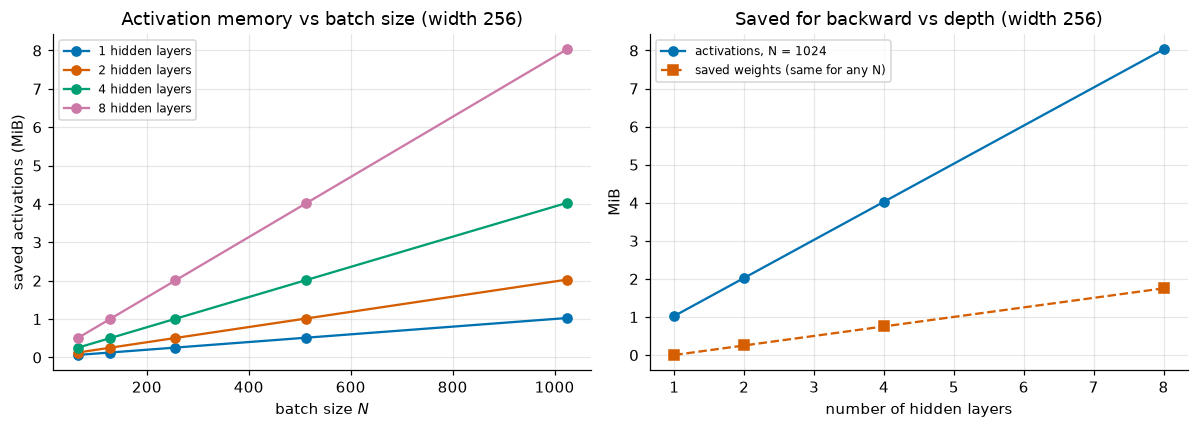

In [28]:
def predicted_activation_bytes(N, D, H, K, depth):
    return 4 * N * (D + depth * H + K) + 8 * N + 4      # float32 activations + int64 labels + one float32 scalar


set_seed(0)
batch_sizes, depths, H_mem = [64, 128, 256, 512, 1024], [1, 2, 4, 8], 256
measured = {}
for depth in depths:
    model = make_mlp(2, H_mem, 3, depth)
    for N_m in batch_sizes:
        act, par = saved_tensors_report(model, torch.randn(N_m, 2), torch.randint(0, 3, (N_m,)))
        measured[depth, N_m] = (act, par)
        check(act == predicted_activation_bytes(N_m, 2, H_mem, 3, depth), f"mismatch at depth {depth}, N {N_m}")
passed("Saved activation bytes match N(D + depth·H + K) floats (+ labels) exactly")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
for c, depth in enumerate(depths):
    ax1.plot(batch_sizes, [measured[depth, n][0] / 2**20 for n in batch_sizes], "o-", color=COLORS[c], label=f"{depth} hidden layers")
ax1.set_xlabel("batch size $N$")
ax1.set_ylabel("saved activations (MiB)")
ax1.set_title(f"Activation memory vs batch size (width {H_mem})")
ax1.legend(fontsize=8)
ax2.plot(depths, [measured[d, 1024][0] / 2**20 for d in depths], "o-", color=COLORS[0], label="activations, N = 1024")
ax2.plot(depths, [measured[d, 1024][1] / 2**20 for d in depths], "s--", color=COLORS[1], label="saved weights (same for any N)")
ax2.set_xlabel("number of hidden layers")
ax2.set_ylabel("MiB")
ax2.set_title(f"Saved for backward vs depth (width {H_mem})")
ax2.legend(fontsize=8)
plt.tight_layout()
plt.show()

Left: activation memory grows in straight lines through the origin with the batch size, with a slope proportional to the depth. Right: at $N = 1024$ it grows linearly with depth, about 1 MiB per hidden layer of width 256 ($4 \times 1024 \times 256$ bytes). The saved weights do not depend on $N$; they are the parameters, which are in memory anyway. For large batches and deep or wide networks the activations dominate — the reason training needs far more memory than inference (which can discard each activation as soon as the next layer has used it). Chapter 5 (notebook 29) trades compute for memory with **activation checkpointing**: store only some activations and recompute the rest during backward.

### Checkpoint 4.1

A network has $D = 784$ inputs, $3$ hidden layers of width $1024$, $K = 10$ classes, and is trained in `float32` with batch size $N = 256$. Using the formula $N(D + LH + K)$, compute `act_floats`, the number of floating-point activation values saved for backward, and `act_mib`, their size in MiB ($2^{20}$ bytes, 4 bytes per value). Then compute `param_count`, the number of parameters (weights and biases), for comparison.

<details>
<summary><b>💡 Hint</b></summary>

$256 \times (784 + 3 \cdot 1024 + 10)$. Parameters: each linear layer has $n_\text{in} n_\text{out} + n_\text{out}$, for the four layers $784 \to 1024 \to 1024 \to 1024 \to 10$.

</details>

In [ ]:
# YOUR CODE HERE
raise NotImplementedError
print(f"activations: {act_floats:,} values = {act_mib:.2f} MiB;  parameters: {param_count:,}")

In [ ]:
_act, _ = saved_tensors_report(make_mlp(784, 1024, 10, 3), torch.randn(256, 784), torch.randint(0, 10, (256,)))
check_close(act_floats, (_act - 8 * 256 - 4) / 4, "act_floats")
check_close(act_mib, (_act - 8 * 256 - 4) / 2**20, "act_mib")
check_close(param_count, sum(p.numel() for p in make_mlp(784, 1024, 10, 3).parameters()), "param_count")
passed("Checkpoint 4.1")

About 3.8 MiB of activations against 2.9 million parameters (11.1 MiB): at this batch size the parameters still dominate. But activation memory grows with $N$ and parameter memory does not: at about 15 KiB of activations per example, the two are equal near $N \approx 750$, and beyond that the activations dominate. (Training also keeps a gradient for every parameter, and optimizers like Adam two more numbers per parameter, notebook 19.)

## 5. A tiny backprop framework

The recipe of Section 4 — every layer has `forward`, which caches what it needs, and `backward(G)`, which returns the downstream gradient — is enough to build a working deep-learning framework in a few dozen lines. Each layer stores its parameter gradients itself. A `Sequential` container calls `forward` on its layers in order and `backward` in **reverse** order.

In [31]:
class Linear:
    """Y = X Wᵀ + b. Parameters initialized like nn.Linear's default."""

    def __init__(self, n_in, n_out, gen, dtype=torch.float32):
        bound = 1 / math.sqrt(n_in)
        self.W = (2 * torch.rand(n_out, n_in, generator=gen, dtype=dtype) - 1) * bound   # (out, in)
        self.b = (2 * torch.rand(n_out, generator=gen, dtype=dtype) - 1) * bound         # (out,)

    def forward(self, X):
        self.X = X                          # cache: the weight gradient needs the input
        return X @ self.W.T + self.b        # (N, out)

    def backward(self, G):                  # G: (N, out)
        self.dW = G.T @ self.X              # (out, in)
        self.db = G.sum(dim=0)              # (out,)
        return G @ self.W                   # (N, in)

    def parameters(self):
        return [self.W, self.b]

    def gradients(self):
        return [self.dW, self.db]


class ReLU:
    def forward(self, A):
        self.mask = A > 0                   # cache: which units were on (1 byte per entry)
        return A * self.mask

    def backward(self, G):
        return G * self.mask

    def parameters(self):
        return []

    def gradients(self):
        return []


class SoftmaxCrossEntropy:
    """Mean cross-entropy of logits Z (N, K) against integer labels y (N,)."""

    def forward(self, Z, y):
        logP = torch.log_softmax(Z, dim=1)                # stable (notebook 10)
        self.P = logP.exp()                               # cache: probabilities
        self.Y = F.one_hot(y, Z.shape[1]).to(Z.dtype)     # cache: one-hot labels
        return -(logP * self.Y).sum(dim=1).mean()

    def backward(self):
        return (self.P - self.Y) / len(self.P)            # G_Z, (N, K)


class Sequential:
    def __init__(self, *layers):
        self.layers = list(layers)

    def forward(self, X):
        for layer in self.layers:
            X = layer.forward(X)
        return X

    def backward(self, G):
        for layer in reversed(self.layers):
            G = layer.backward(G)
        return G

    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]

    def gradients(self):
        return [g for layer in self.layers for g in layer.gradients()]


def sgd_step(model, lr):
    for p, g in zip(model.parameters(), model.gradients()):
        p -= lr * g                         # in place: the layers hold these same tensors

Before training, test it: a network with two hidden layers of width 64 on the spirals, gradients compared with autograd at the same parameters.

In [32]:
def framework_net(gen, dtype=torch.float32, width=64, activation=ReLU):
    return Sequential(Linear(2, width, gen, dtype), activation(), Linear(width, width, gen, dtype), activation(),
                      Linear(width, 3, gen, dtype))


def autograd_forward(param_list, X, act=torch.relu):
    """The same network as plain tensor operations, for autograd: [W1, b1, W2, b2, W3, b3]."""
    n_layers = len(param_list) // 2
    for k in range(n_layers):
        X = X @ param_list[2 * k].T + param_list[2 * k + 1]
        if k < n_layers - 1:
            X = act(X)
    return X


net = framework_net(torch.Generator().manual_seed(0), dtype=f64)
ce = SoftmaxCrossEntropy()
loss_fw = ce.forward(net.forward(X64), y64)
net.backward(ce.backward())

twin_params = [p.clone().requires_grad_(True) for p in net.parameters()]
loss_ag = F.cross_entropy(autograd_forward(twin_params, X64), y64)
loss_ag.backward()
print(f"loss: framework {loss_fw.item():.12f}, autograd {loss_ag.item():.12f}")
for name, g, q in zip(["W1", "b1", "W2", "b2", "W3", "b3"], net.gradients(), twin_params):
    print(f"{name}: shape {str(tuple(g.shape)):8s}  max |framework - autograd| = {(g - q.grad).abs().max().item():.1e}")
    check_close(g, q.grad, name, rtol=1e-10, atol=1e-14)
passed("Framework gradients match autograd")

loss: framework 1.100833726410, autograd 1.100833726410
W1: shape (64, 2)   max |framework - autograd| = 7.6e-19
b1: shape (64,)     max |framework - autograd| = 1.7e-18
W2: shape (64, 64)  max |framework - autograd| = 7.4e-18
b2: shape (64,)     max |framework - autograd| = 4.3e-18
W3: shape (3, 64)   max |framework - autograd| = 1.4e-17
b3: shape (3,)      max |framework - autograd| = 6.9e-18
✅ Framework gradients match autograd passed


Three layers deep, and still exact to `float64` rounding: the framework never needed a formula for the network as a whole, only for each layer. That is the point of the layer-wise formulation — any stack of these layers, in any order and depth, gets correct gradients for free.

### Training it, next to an autograd twin

Now train it on the three-class spirals with full-batch gradient descent ($\eta = 0.5$, 3000 steps) in `float32`. Alongside, train a **twin**: the same initial parameters and data, the same update rule, but with gradients from autograd. If the framework is right, both should follow the same path.

In [33]:
LR, STEPS = 0.5, 3000


def train_with_twin(dtype, steps=STEPS, lr=LR, seed=0, check_every=250):
    """Train the framework net and an autograd twin side by side.
    Returns the framework net, both loss curves, the max parameter difference after each step, and the
    relative gradient difference when both gradients are computed at the framework's own parameters, and the
    first step at which the two runs disagree about whether some ReLU unit is on for some example."""
    net = framework_net(torch.Generator().manual_seed(seed), dtype=dtype)
    twin = [p.clone().requires_grad_(True) for p in net.parameters()]
    X, ce = X_sp.to(dtype), SoftmaxCrossEntropy()
    losses, twin_losses, param_diff, grad_rel, mask_flips = [], [], [], [], []
    for step in range(steps):
        losses.append(ce.forward(net.forward(X), y_sp).item())
        net.backward(ce.backward())
        if step % check_every == 0:          # gradient check at the framework's current parameters
            here = [p.clone().requires_grad_(True) for p in net.parameters()]
            g_auto = torch.autograd.grad(F.cross_entropy(autograd_forward(here, X), y_sp), here)
            num = math.sqrt(sum(((g - a) ** 2).sum().item() for g, a in zip(net.gradients(), g_auto)))
            den = math.sqrt(sum((a ** 2).sum().item() for a in g_auto))
            grad_rel.append((step, num / den))
        sgd_step(net, lr)

        twin_loss = F.cross_entropy(autograd_forward(twin, X), y_sp)
        twin_losses.append(twin_loss.item())
        with torch.no_grad():                # do the two runs disagree about which ReLUs are on?
            A1_t = X @ twin[0].T + twin[1]
            A2_t = torch.relu(A1_t) @ twin[2].T + twin[3]
            mask_flips.append(((A1_t > 0) != net.layers[1].mask).sum().item() + ((A2_t > 0) != net.layers[3].mask).sum().item())
        grads = torch.autograd.grad(twin_loss, twin)
        with torch.no_grad():
            for p, g in zip(twin, grads):
                p -= lr * g
        param_diff.append(max((p - q).abs().max().item() for p, q in zip(net.parameters(), twin)))
    first_flip = next((s for s, m in enumerate(mask_flips) if m > 0), None)
    return net, losses, twin_losses, param_diff, grad_rel, first_flip


t0 = time.perf_counter()
net32, losses32, twin32, diff32, grad_rel32, flip32 = train_with_twin(torch.float32)
print(f"float32 run: {time.perf_counter() - t0:.1f} s")
with torch.no_grad():
    acc32 = (net32.forward(X_sp).argmax(dim=1) == y_sp).float().mean().item()
print(f"framework: initial loss {losses32[0]:.4f} (ln 3 = {math.log(3):.4f}), final loss {losses32[-1]:.4f}, "
      f"training accuracy {acc32:.3f}")
print("relative gradient difference at the same parameters:", ", ".join(f"step {s}: {r:.1e}" for s, r in grad_rel32[::3]))
print("max |parameter difference| after step:", ", ".join(f"{s}: {diff32[s - 1]:.1e}" for s in [1, 10, 100, 500, 1000, 2000, 3000]))
print("first step at which the two runs disagree about a ReLU being on:", flip32)

float32 run: 2.5 s
framework: initial loss 1.1096 (ln 3 = 1.0986), final loss 0.0908, training accuracy 0.956
relative gradient difference at the same parameters: step 0: 2.8e-07, step 750: 7.0e-08, step 1500: 5.5e-07, step 2250: 1.0e-07
max |parameter difference| after step: 1: 7.5e-09, 10: 3.0e-08, 100: 2.1e-04, 500: 6.2e-02, 1000: 5.2e-01, 2000: 1.4e+00, 3000: 1.8e+00
first step at which the two runs disagree about a ReLU being on: 83


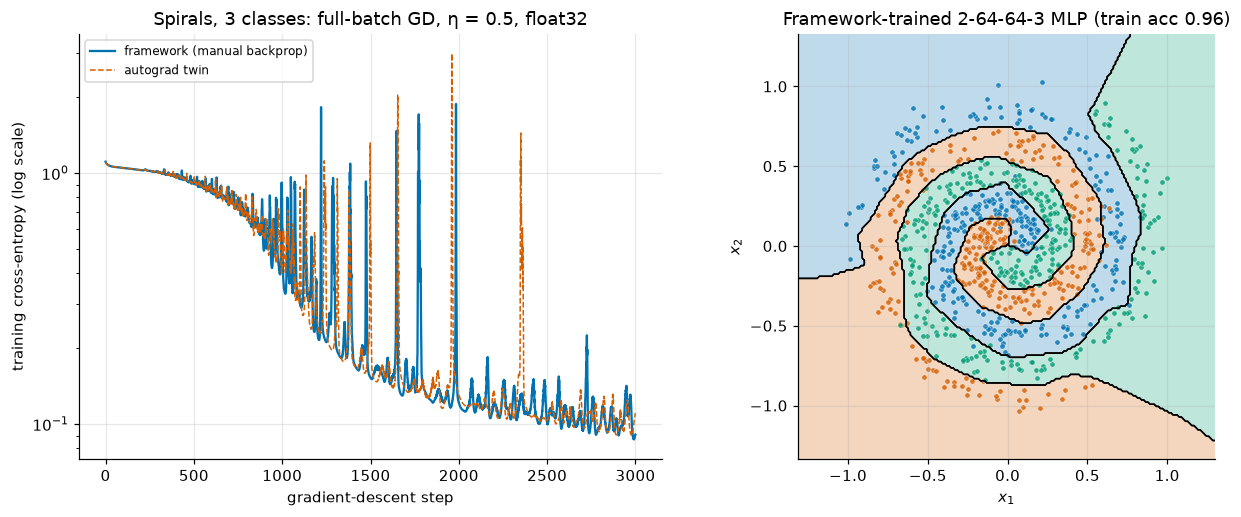

In [34]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8))
ax1.plot(losses32, color=COLORS[0], lw=1.5, label="framework (manual backprop)")
ax1.plot(twin32, color=COLORS[1], lw=1, ls="--", label="autograd twin")
ax1.set_yscale("log")
ax1.set_xlabel("gradient-descent step")
ax1.set_ylabel("training cross-entropy (log scale)")
ax1.set_title(f"Spirals, 3 classes: full-batch GD, η = {LR}, float32")
ax1.legend(fontsize=8)
plot_decision_boundary(lambda G: net32.forward(G).argmax(dim=1), X_sp, y_sp, ax=ax2,
                       title=f"Framework-trained 2-64-64-3 MLP (train acc {acc32:.2f})")
plt.tight_layout()
plt.show()

Left: the framework trains the network from the initial loss $\approx \ln 3$ (notebook 13's check) down to about 0.1. The two curves lie on top of each other for the first several hundred steps; later both show sharp spikes, but at different steps. (The spikes mean that $\eta = 0.5$ is close to the stability limit for this loss — the $\eta < 2/\lambda_{\max}$ of notebook 03; notebook 19 studies better optimizers and schedules.) Right: the learned regions follow the spiral arms. Our thirty-line framework trains a real classifier.

Why do the curves separate at all, if the gradients are right? The printout answers it. At the *same* parameters, framework and autograd gradients agree to a relative difference of about $10^{-7}$ throughout — `float32` rounding (the two compute the same sums in slightly different orders). But the *trajectories* drift apart: their parameter difference starts at the rounding level and grows. Let's plot that growth in `float32` and `float64`:

float64 run: 3.4 s;  relative gradient difference at the same parameters: max 7.7e-16


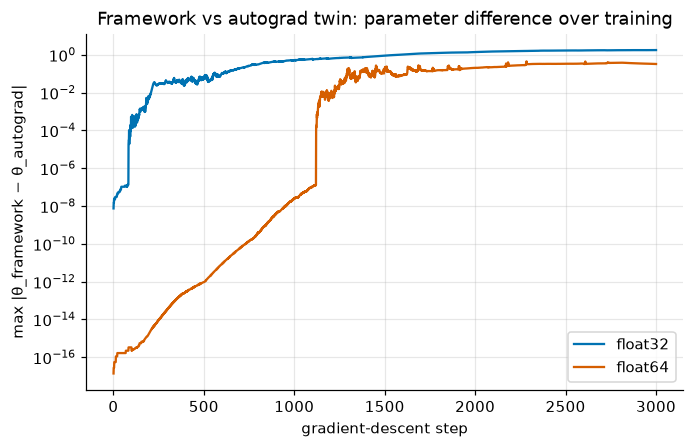

float64 max |parameter difference| after step: 1: 1.4e-17, 10: 5.6e-17, 100: 3.3e-16, 500: 9.5e-13, 1000: 2.6e-08, 2000: 2.0e-01, 3000: 3.2e-01
first step with a ReLU disagreement: float32 83, float64 1120


In [35]:
t0 = time.perf_counter()
_, _, _, diff64, grad_rel64, flip64 = train_with_twin(f64)
print(f"float64 run: {time.perf_counter() - t0:.1f} s;  relative gradient difference at the same parameters: "
      f"max {max(r for _, r in grad_rel64):.1e}")

fig, ax = plt.subplots(figsize=(7, 4.2))
steps_axis = range(1, STEPS + 1)
ax.semilogy(steps_axis, [max(d, 1e-18) for d in diff32], color=COLORS[0], label="float32")
ax.semilogy(steps_axis, [max(d, 1e-18) for d in diff64], color=COLORS[1], label="float64")
ax.set_xlabel("gradient-descent step")
ax.set_ylabel("max |θ_framework − θ_autograd|")
ax.set_title("Framework vs autograd twin: parameter difference over training")
ax.legend()
plt.show()
print("float64 max |parameter difference| after step:", ", ".join(f"{s}: {diff64[s - 1]:.1e}" for s in [1, 10, 100, 500, 1000, 2000, 3000]))
print(f"first step with a ReLU disagreement: float32 {flip32}, float64 {flip64}")

Both runs start identical up to rounding error — about $10^{-8}$ in `float32`, $10^{-17}$ in `float64`. Then two things happen. Between events, the difference grows steadily: in `float64` it climbs by about nine orders of magnitude over the first thousand steps, a nearly straight line on the log scale, i.e. exponential growth. And at a few moments it **jumps** by several orders of magnitude at once. The printout identifies the jumps: the first big jump in each curve comes at the first step where the two runs disagree about whether some ReLU unit is on for some training example. Once that happens, the two runs are computing slightly different functions, and the gap becomes as large as the parameters' own changes. `float64` delays this because its differences start about $10^9$ times smaller and take longer to bring a pre-activation to the other side of zero.

This is not a bug in either implementation. Gradient descent with a large learning rate on a non-convex loss is **sensitive to tiny perturbations**: a difference in the last bit of one gradient changes the next parameters slightly, which changes the next gradients slightly more, and a ReLU that switches in one run but not the other turns a tiny difference into a large one. Two correct implementations agree step by step only up to that amplified rounding. The lesson for testing: **compare gradients at the same parameters** (as `grad_rel` does, and as Section 3 did) or compare trajectories over a short horizon; do not expect two long training runs to agree to many digits.

## 6. The cost of backpropagation

**Counting multiply-adds.** For one dense layer with a batch of $N$, $n_\text{in}$ inputs and $n_\text{out}$ outputs:

- **Forward** $Y = XW^\top + \mathbf b$: each of the $N\,n_\text{out}$ outputs is a dot product of length $n_\text{in}$: $N\,n_\text{in}\,n_\text{out}$ multiply-adds.
- **Backward**, weight gradient $G^\top X$: $n_\text{out}\,n_\text{in}$ entries, each a sum over $N$ examples: $N\,n_\text{in}\,n_\text{out}$.
- **Backward**, input gradient $G W$: $N\,n_\text{in}$ entries, each a sum over $n_\text{out}$: $N\,n_\text{in}\,n_\text{out}$.

The bias and ReLU terms are $O(N\,n_\text{out})$, negligible next to these. So **backward ≈ 2 × forward** for a dense layer — one matrix product of the forward's size for the weights, one for the input — and a full training step (forward + backward) costs about **3 forward passes**. The first layer can skip its input gradient, so for it backward is 1 × forward.

This is the concrete form of the general result quoted in notebook 05: reverse mode computes the gradient with respect to *all* parameters for a small constant multiple of one forward evaluation.

### Checkpoint 6.1

Write `dense_layer_macs(N, n_in, n_out, need_input_grad)` returning a tuple `(forward_macs, backward_macs)` of multiply-adds for one dense layer (ignore the bias). Then use it to compute `train_step_ratio`: (forward + backward) / forward multiply-adds for the 2-64-64-3 spiral network on its $N = 900$ points, where the first layer does not need its input gradient.

<details>
<summary><b>💡 Hint</b></summary>

Forward: `N * n_in * n_out`. Backward: the same for the weight gradient, plus the same again if `need_input_grad`. For the ratio, sum over the three layers `(2, 64)`, `(64, 64)`, `(64, 3)`, with `need_input_grad=False` only for the first.

</details>

In [ ]:
def dense_layer_macs(N, n_in, n_out, need_input_grad=True):
    # YOUR CODE HERE
    raise NotImplementedError


# YOUR CODE HERE
raise NotImplementedError
print(f"(forward + backward) / forward = {train_step_ratio:.3f}")

In [ ]:
check(tuple(dense_layer_macs(10, 3, 4, True)) == (120, 240), "dense_layer_macs(10, 3, 4, True) should be (120, 240)")
check(tuple(dense_layer_macs(10, 3, 4, False)) == (120, 120), "dense_layer_macs(10, 3, 4, False) should be (120, 120)")
_f = 900 * (2 * 64 + 64 * 64 + 64 * 3)
check_close(train_step_ratio, (_f + 2 * _f - 900 * 2 * 64) / _f, "train_step_ratio")
passed("Checkpoint 6.1")

Just under 3 (about 2.97): the skipped input gradient of the tiny first layer barely matters.

### Timing it

Operation counts are not run times — small matrix products are dominated by overheads, and libraries are faster at some shapes than others — so we measure. For MLPs with 3 hidden layers of increasing width on a batch of 1024, we time the forward pass alone and forward + backward, for autograd (`nn.Sequential`) and for our framework. Each figure is the median of several repeats. These timings are **indicative only**: they depend on the machine, the number of threads, and what else is running.

 width  autograd fwd    fwd+bwd   ratio  |  framework fwd    fwd+bwd   ratio
    32        0.07ms     0.26ms    3.73  |         0.14ms     0.28ms    1.91
   128        0.26ms     0.65ms    2.49  |         0.51ms     0.86ms    1.69


   512        1.15ms     3.24ms    2.82  |         1.66ms     3.86ms    2.32


  1024        3.31ms     9.55ms    2.89  |         4.18ms    10.63ms    2.54


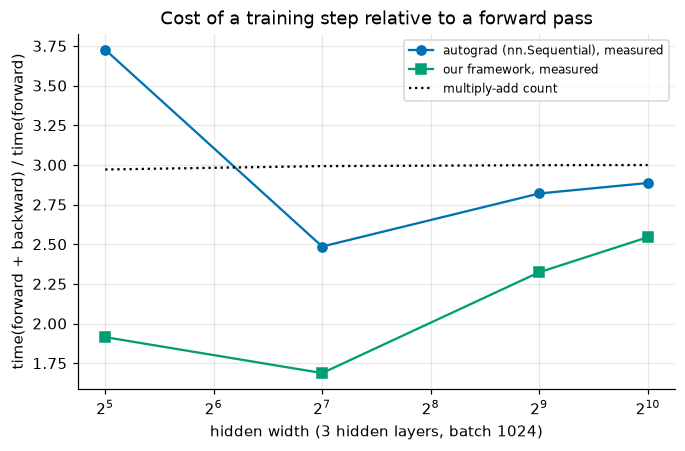

In [38]:
def median_time(fn, repeats=9):
    fn()                                                 # warm-up
    times = []
    for _ in range(repeats):
        start = time.perf_counter()
        fn()
        times.append(time.perf_counter() - start)
    return sorted(times)[len(times) // 2]


set_seed(0)
widths, N_t = [32, 128, 512, 1024], 1024
X_t, y_t = torch.randn(N_t, 2), torch.randint(0, 3, (N_t,))
ratios_autograd, ratios_framework = [], []
print(f"{'width':>6s}  {'autograd fwd':>12s}  {'fwd+bwd':>9s}  {'ratio':>6s}  |  {'framework fwd':>13s}  {'fwd+bwd':>9s}  {'ratio':>6s}")
for width in widths:
    model = make_mlp(2, width, 3, depth=3)

    def fwd_only():
        with torch.no_grad():
            F.cross_entropy(model(X_t), y_t)

    def fwd_bwd():
        model.zero_grad(set_to_none=True)
        F.cross_entropy(model(X_t), y_t).backward()

    fw_net = Sequential(Linear(2, width, torch.Generator().manual_seed(0)), ReLU(),
                        Linear(width, width, torch.Generator().manual_seed(1)), ReLU(),
                        Linear(width, width, torch.Generator().manual_seed(2)), ReLU(),
                        Linear(width, 3, torch.Generator().manual_seed(3)))
    fw_ce = SoftmaxCrossEntropy()

    def fw_fwd_only():
        fw_ce.forward(fw_net.forward(X_t), y_t)

    def fw_fwd_bwd():
        fw_ce.forward(fw_net.forward(X_t), y_t)
        fw_net.backward(fw_ce.backward())

    t_f, t_fb = median_time(fwd_only), median_time(fwd_bwd)
    t_ff, t_ffb = median_time(fw_fwd_only), median_time(fw_fwd_bwd)
    ratios_autograd.append(t_fb / t_f)
    ratios_framework.append(t_ffb / t_ff)
    print(f"{width:6d}  {1e3 * t_f:10.2f}ms  {1e3 * t_fb:7.2f}ms  {t_fb / t_f:6.2f}  |  {1e3 * t_ff:11.2f}ms  {1e3 * t_ffb:7.2f}ms  {t_ffb / t_ff:6.2f}")

macs_ratio = []
for width in widths:
    layer_shapes = [(2, width, False), (width, width, True), (width, width, True), (width, 3, True)]
    counts = [(N_t * a * b, N_t * a * b * (2 if need else 1)) for a, b, need in layer_shapes]
    macs_ratio.append(sum(f + b for f, b in counts) / sum(f for f, _ in counts))

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(widths, ratios_autograd, "o-", color=COLORS[0], label="autograd (nn.Sequential), measured")
ax.plot(widths, ratios_framework, "s-", color=COLORS[2], label="our framework, measured")
ax.plot(widths, macs_ratio, "k:", label="multiply-add count")
ax.set_xscale("log", base=2)
ax.set_xlabel("hidden width (3 hidden layers, batch 1024)")
ax.set_ylabel("time(forward + backward) / time(forward)")
ax.set_title("Cost of a training step relative to a forward pass")
ax.legend(fontsize=8)
plt.show()

As the width grows and the large matrix products take over the run time, autograd's measured ratio moves towards the multiply-add prediction of about 3. Our framework's ratio stays somewhat lower: its `forward` does extra work that its `backward` then reuses (it builds the one-hot matrix, exponentiates the log-probabilities, and stores the mask), so its forward pass is heavier and its backward lighter. At small widths both ratios wander, because the arithmetic is so cheap that fixed per-operation overheads make up much of the time. Your numbers will differ, but the message is robust: **a gradient with respect to every parameter costs a small constant number of forward passes**, never a number that grows with the parameter count.

### Compared with finite differences

Notebook 03's central differences need two forward passes **per parameter**. For the 2-64-64-3 spiral network that is $2 \times 4547 = 9094$ forward passes for one gradient. We can afford to do it once, in `float64`, and compare both cost and accuracy with backprop:

In [39]:
net_fd = framework_net(torch.Generator().manual_seed(0), dtype=f64)
ce_fd = SoftmaxCrossEntropy()
theta0 = [p.clone() for p in net_fd.parameters()]
n_params = sum(p.numel() for p in theta0)


def loss_at(net, X, y):
    return SoftmaxCrossEntropy().forward(net.forward(X), y).item()


start = time.perf_counter()
ce_fd.forward(net_fd.forward(X64), y64)
net_fd.backward(ce_fd.backward())
t_backprop = time.perf_counter() - start
g_bp = torch.cat([g.flatten() for g in net_fd.gradients()])

h_fd = 1e-6
start = time.perf_counter()
g_fd = torch.zeros(n_params, dtype=f64)
idx = 0
for p in net_fd.parameters():
    flat = p.view(-1)                       # a view: writing into it changes the layer's parameter
    for j in range(flat.numel()):
        old = flat[j].item()
        flat[j] = old + h_fd
        L_plus = loss_at(net_fd, X64, y64)
        flat[j] = old - h_fd
        L_minus = loss_at(net_fd, X64, y64)
        flat[j] = old
        g_fd[idx] = (L_plus - L_minus) / (2 * h_fd)
        idx += 1
t_fd = time.perf_counter() - start

print(f"parameters: {n_params};  finite differences used {2 * n_params} forward passes")
print(f"backprop (forward + backward): {1e3 * t_backprop:8.2f} ms")
print(f"finite differences:            {1e3 * t_fd:8.0f} ms   ({t_fd / t_backprop:,.0f}× slower)")
print(f"max |backprop - finite differences| = {(g_bp - g_fd).abs().max().item():.1e}   (largest gradient entry {g_bp.abs().max().item():.1e})")

parameters: 4547;  finite differences used 9094 forward passes
backprop (forward + backward):     0.68 ms
finite differences:                2577 ms   (3,808× slower)
max |backprop - finite differences| = 2.6e-10   (largest gradient entry 5.0e-02)


Finite differences take thousands of times longer for a network with only 4547 parameters, and they are only approximate (agreeing with backprop to about $10^{-10}$, the accuracy of a `float64` central difference from notebook 03). The cost ratio grows **in proportion to the number of parameters**: for a model with $10^9$ parameters, finite differences would need $2 \times 10^9$ forward passes per gradient, backprop about two passes' worth of work. That gap — a constant versus a factor proportional to the parameter count — is why every deep network is trained with backpropagation, and finite differences are used only to *check* it, on tiny cases.

## 7. A brief history

The algorithm of this notebook was discovered more than once, in different fields:

- **Reverse-mode automatic differentiation** for general computer programs — compute all partial derivatives of one output by sweeping backwards through the stored intermediate results — was described by **Seppo Linnainmaa** in his 1970 master's thesis at the University of Helsinki (as a way to estimate accumulated rounding errors; published in *BIT* in 1976). Related backward "adjoint" calculations had appeared in optimal control in the early 1960s (Kelley 1960, Bryson 1961).
- **Paul Werbos** proposed using such backward derivative calculations to train multi-stage models in his 1974 Harvard PhD thesis, and in a 1982 paper described their application to neural networks in essentially the modern form.
- **David Rumelhart, Geoffrey Hinton and Ronald Williams** (1986, *Nature*, "Learning representations by back-propagating errors") showed experimentally that backpropagation trains the hidden units of multilayer networks to discover useful internal representations. This paper, and the accompanying chapter in the *Parallel Distributed Processing* volumes, made the method widely known and gave it its name in neural-network practice. (Similar derivations appeared independently around the same time, e.g. Parker 1985 and LeCun 1985.)

Modern frameworks (PyTorch's autograd included) are implementations of Linnainmaa's general reverse mode: they differentiate whatever program you write, not only layered networks — exactly the "every operation has a backward" view of Section 4.

## Exercises

### Exercise 1 (modify): from ReLU to tanh

Below is a copy of the framework's `ReLU` class, renamed `Tanh`. **Modify** its `forward` and `backward` so that it computes $\tanh$, with the backward pass using $\tanh'(a) = 1 - \tanh^2(a)$ (notebook 03). Cache the **output** $\tanh(a)$, not the input — the derivative can be written in terms of it. The check compares gradients through a tanh network with autograd.

Then run the experiment cell, which trains the 2-64-64-3 network with ReLU and with tanh (same initial weights, $\eta = 0.5$, 3000 steps) and plots both. Answer in the markdown cell: which trains faster here, and which reaches the lower final loss? Do the decision regions look different? Offer an explanation based on the backward passes of the two activations.

<details>
<summary><b>💡 Hint</b></summary>

`forward`: `self.out = torch.tanh(A)`, return it. `backward`: `return G * (1 - self.out ** 2)`. For the explanation, compare the two local derivatives: ReLU's is exactly 1 for active units; tanh's is at most 1 and much smaller when $|a|$ is large. Look also at the shape of the boundaries: ReLU networks are piecewise linear (notebook 12).

</details>

In [ ]:
class Tanh:
    def forward(self, A):
        # YOUR CODE HERE
        raise NotImplementedError

    def backward(self, G):
        # YOUR CODE HERE
        raise NotImplementedError

    def parameters(self):
        return []

    def gradients(self):
        return []

In [ ]:
_net = framework_net(torch.Generator().manual_seed(3), dtype=f64, activation=Tanh)
_ce = SoftmaxCrossEntropy()
check_close(_net.layers[1].forward(torch.tensor([-1.0, 0.0, 2.0], dtype=f64)), torch.tanh(torch.tensor([-1.0, 0.0, 2.0], dtype=f64)), "Tanh.forward")
_out = _net.forward(X64[:50])
_ce.forward(_out, y64[:50])
_net.backward(_ce.backward())
_tw = [p.clone().requires_grad_(True) for p in _net.parameters()]
F.cross_entropy(autograd_forward(_tw, X64[:50], act=torch.tanh), y64[:50]).backward()
for _name, _g, _q in zip(["W1", "b1", "W2", "b2", "W3", "b3"], _net.gradients(), _tw):
    check_close(_g, _q.grad, f"gradient of {_name} through Tanh", rtol=1e-9, atol=1e-13)
passed("Exercise 1 (Tanh layer)")

In [ ]:
def train_framework(activation, steps=STEPS, lr=LR, seed=0):
    net = framework_net(torch.Generator().manual_seed(seed), activation=activation)
    ce, losses = SoftmaxCrossEntropy(), []
    for _ in range(steps):
        losses.append(ce.forward(net.forward(X_sp), y_sp).item())
        net.backward(ce.backward())
        sgd_step(net, lr)
    return net, losses


fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for c, act in enumerate([ReLU, Tanh]):
    net_e, losses_e = train_framework(act)
    with torch.no_grad():
        acc_e = (net_e.forward(X_sp).argmax(dim=1) == y_sp).float().mean().item()
    print(f"{act.__name__:5s}: loss after 300 / 1000 / 3000 steps = {losses_e[299]:.3f} / {losses_e[999]:.3f} / {losses_e[-1]:.3f}, "
          f"training accuracy {acc_e:.3f}")
    axes[0].plot(losses_e, color=COLORS[c], label=act.__name__)
    plot_decision_boundary(lambda G: net_e.forward(G).argmax(dim=1), X_sp, y_sp, ax=axes[1 + c],
                           title=f"{act.__name__} network (train acc {acc_e:.2f})")
axes[0].set_yscale("log")
axes[0].set_xlabel("gradient-descent step")
axes[0].set_ylabel("training cross-entropy (log scale)")
axes[0].set_title(f"ReLU vs tanh, η = {LR}")
axes[0].legend()
plt.tight_layout()
plt.show()

*Your answer:*

### Exercise 2 (implement): a mean-squared-error loss layer

For regression, the framework needs a loss layer like `SoftmaxCrossEntropy` but for the mean squared error over all $N \times K$ outputs (notebook 06):

$$L = \frac{1}{NK}\sum_{i=1}^N\sum_{k=1}^K (Z_{ik} - T_{ik})^2,$$

with predictions $Z$ and targets $T$, both of shape $(N, K)$. Implement `MSELoss` with `forward(Z, T)` returning $L$ (a 0-d tensor) and caching what the backward needs, and `backward()` returning $G_Z$, shape $(N, K)$. Derive $G_Z$ in index form first. The check compares with `F.mse_loss` and autograd, including through a whole framework network.

<details>
<summary><b>💡 Hint</b></summary>

$Z_{ik}$ appears in exactly one term of the sum, so $\partial L/\partial Z_{ik} = \frac{2}{NK}(Z_{ik} - T_{ik})$. Cache the difference $Z - T$ in `forward`; `Z.numel()` is $NK$.

</details>

In [ ]:
class MSELoss:
    def forward(self, Z, T):
        # YOUR CODE HERE
        raise NotImplementedError

    def backward(self):
        # YOUR CODE HERE
        raise NotImplementedError

In [ ]:
_gen = torch.Generator().manual_seed(9)
_Z = torch.randn(6, 2, dtype=f64, generator=_gen, requires_grad=True)
_T = torch.randn(6, 2, dtype=f64, generator=_gen)
_mse = MSELoss()
_L = _mse.forward(_Z.detach(), _T)
check_close(_L, F.mse_loss(_Z.detach(), _T), "MSELoss.forward")
_G = _mse.backward()
check_shape(_G, (6, 2), "MSELoss.backward()")
F.mse_loss(_Z, _T).backward()
check_close(_G, _Z.grad, "MSELoss.backward()")
# through a whole network: a 2-16-16-2 regression net
_net = Sequential(Linear(2, 16, _gen, f64), ReLU(), Linear(16, 16, _gen, f64), ReLU(), Linear(16, 2, _gen, f64))
_X, _T = torch.randn(40, 2, dtype=f64, generator=_gen), torch.randn(40, 2, dtype=f64, generator=_gen)
_mse.forward(_net.forward(_X), _T)
_net.backward(_mse.backward())
_tw = [p.clone().requires_grad_(True) for p in _net.parameters()]
F.mse_loss(autograd_forward(_tw, _X), _T).backward()
for _g, _q in zip(_net.gradients(), _tw):
    check_close(_g, _q.grad, "network gradient with MSELoss", rtol=1e-9, atol=1e-13)
passed("Exercise 2")

### Exercise 3 (debug): a backward pass that trains, slowly

`mlp_backward_v2` is meant to compute the same gradients as `mlp_backward` of Section 2. The buggy version (in the comments) runs without errors, returns tensors of exactly the right shapes, and gradient descent with it even lowers the loss — just much more slowly than it should. It contains **two** bugs. Find them and write the corrected body.

<details>
<summary><b>💡 Hint</b></summary>

Compare each line with the table at the end of Section 2, and compare each returned gradient with autograd separately: which ones are wrong, and by what factor or pattern? One bug confuses a nonlinearity's *output* with its *derivative*; the other applies the batch average twice.

</details>

In [ ]:
def mlp_backward_v2(params, cache, Z, y):
    N, K = Z.shape
    # Buggy version:
    #     G_Z = (torch.softmax(Z, dim=1) - F.one_hot(y, K).to(Z.dtype)) / N
    #     dW2 = G_Z.T @ cache["H1"]
    #     db2 = G_Z.mean(dim=0)
    #     G_H1 = G_Z @ params["W2"]
    #     G_A1 = G_H1 * cache["H1"]
    #     dW1 = G_A1.T @ cache["X"]
    #     db1 = G_A1.sum(dim=0)
    # YOUR CODE HERE
    raise NotImplementedError
    return {"W1": dW1, "b1": db1, "W2": dW2, "b2": db2}

In [ ]:
_p = init_params(2, 64, 3, torch.Generator().manual_seed(10), dtype=f64)
_Z, _c = mlp_forward(_p, X64)
_mine = mlp_backward_v2(_p, _c, _Z, y64)
_leaves = {k: v.clone().requires_grad_(True) for k, v in _p.items()}
F.cross_entropy(mlp_forward(_leaves, X64)[0], y64).backward()
for _k in ["W1", "b1", "W2", "b2"]:
    check_close(_mine[_k], _leaves[_k].grad, f"gradient of {_k}", rtol=1e-9, atol=1e-14)
passed("Exercise 3")

To see what each bug does, here is the buggy backward run directly: its gradients compared with the correct ones, and 2000 steps of training with each.

In [47]:
def mlp_backward_buggy(params, cache, Z, y, bias_bug=True, mask_bug=True):
    N, K = Z.shape
    G_Z = (torch.softmax(Z, dim=1) - F.one_hot(y, K).to(Z.dtype)) / N
    G_H1 = G_Z @ params["W2"]
    G_A1 = G_H1 * (cache["H1"] if mask_bug else (cache["A1"] > 0))
    return {"W1": G_A1.T @ cache["X"], "b1": G_A1.sum(dim=0), "W2": G_Z.T @ cache["H1"],
            "b2": G_Z.mean(dim=0) if bias_bug else G_Z.sum(dim=0)}


_p = init_params(2, 64, 3, torch.Generator().manual_seed(10), dtype=f64)
_Z, _c = mlp_forward(_p, X64)
_good, _bad = mlp_backward(_p, _c, _Z, y64), mlp_backward_buggy(_p, _c, _Z, y64)
for _k in ["W1", "b1", "W2", "b2"]:
    cos = F.cosine_similarity(_good[_k].flatten(), _bad[_k].flatten(), dim=0).item()
    print(f"{_k}: |buggy| / |correct| = {_bad[_k].norm().item() / _good[_k].norm().item():.4f},  cosine similarity {cos:+.3f}")


def train_two_layer(backward_fn, steps=2000, lr=0.5):
    p = init_params(2, 64, 3, torch.Generator().manual_seed(10))
    for _ in range(steps):
        Z, cache = mlp_forward(p, X_sp)
        g = backward_fn(p, cache, Z, y_sp)
        for k in p:
            p[k] = p[k] - lr * g[k]
    Z, _ = mlp_forward(p, X_sp)
    return F.cross_entropy(Z, y_sp).item(), (Z.argmax(dim=1) == y_sp).float().mean().item()


for label, fn in [("correct", mlp_backward),
                  ("bias bug only", lambda *a: mlp_backward_buggy(*a, mask_bug=False)),
                  ("mask bug only", lambda *a: mlp_backward_buggy(*a, bias_bug=False)),
                  ("both bugs", mlp_backward_buggy)]:
    L_end, acc_end = train_two_layer(fn)
    print(f"{label:14s}: loss after 2000 steps {L_end:.4f}, training accuracy {acc_end:.3f}")

W1: |buggy| / |correct| = 0.4942,  cosine similarity +0.846
b1: |buggy| / |correct| = 0.3721,  cosine similarity +0.918
W2: |buggy| / |correct| = 1.0000,  cosine similarity +1.000
b2: |buggy| / |correct| = 0.0011,  cosine similarity +1.000


correct       : loss after 2000 steps 0.8061, training accuracy 0.597


bias bug only : loss after 2000 steps 0.8086, training accuracy 0.606


mask bug only : loss after 2000 steps 1.0465, training accuracy 0.470


both bugs     : loss after 2000 steps 1.0460, training accuracy 0.471


### Exercise 4 (investigate): how accurate are gradients in `float32`?

Section 5 found that framework and autograd gradients differ by about $10^{-7}$ (relative) in `float32`. Is that a bug, or the best `float32` can do? And why must `gradcheck` run in `float64`? The scaffold computes, for the two-layer spiral network at the random parameters of Section 3:

- the exact gradient (to `float64` rounding) as a reference;
- the manual and the autograd gradient in `float32`, with their relative errors against the reference and against each other;
- central finite differences $\frac{L(\theta + h e_j) - L(\theta - h e_j)}{2h}$ for 30 randomly chosen entries of $W_1$, in `float32` and in `float64`, for step sizes $h$ from $10^{-1}$ to $10^{-9}$, with their relative errors.

Run it and answer in the markdown cell:

1. How large are the `float32` errors of the manual and the autograd gradients, compared with each other and with `float32`'s machine epsilon ($\approx 1.2 \times 10^{-7}$)? What tolerance would you use to compare a `float32` manual backward with autograd?
2. For each dtype, which $h$ gives the most accurate finite difference, and how accurate is it? Explain the U-shape using notebook 03's two error sources.
3. Why must `gradcheck` use `float64`? What would happen to a check of a *correct* backward in `float32`?

<details>
<summary><b>💡 Hint</b></summary>

Truncation error of the central difference shrinks like $h^2$; rounding error grows like $\epsilon\,|L| / h$, with $\epsilon$ the machine epsilon of the dtype. The minimum of their sum is near $h \approx \epsilon^{1/3}$. With ReLU, a large $h$ can also push a pre-activation across 0 and change which units are on.

</details>

param  manual32 vs exact  autograd32 vs exact  manual32 vs autograd32
W1               4.5e-07              4.1e-07                 1.3e-07
b1               2.3e-07              2.8e-07                 1.8e-07
W2               1.3e-06              1.3e-06                 2.2e-07
b2               9.8e-08              1.8e-07                 1.5e-07
finite differences in torch.float32: best h = 1e-02, relative error 7.0e-03
finite differences in torch.float64: best h = 1e-05, relative error 2.9e-09


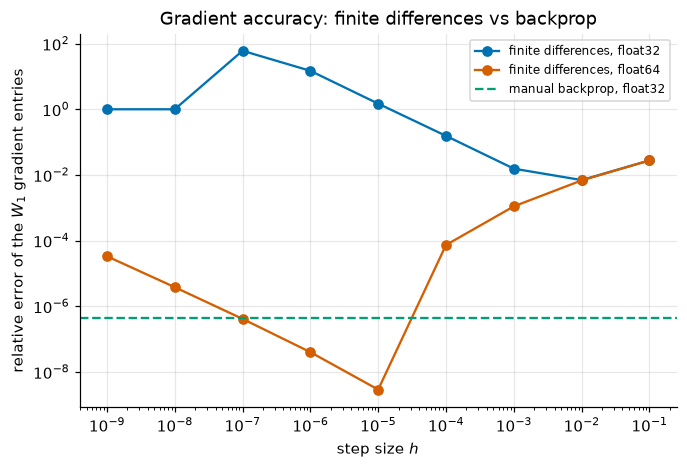

In [48]:
def rel_err(a, b):
    return ((a.double() - b.double()).norm() / b.double().norm()).item()


p64 = params64
Z_ref, cache_ref = mlp_forward(p64, X64)
ref = mlp_backward(p64, cache_ref, Z_ref, y64)

p32 = {k: v.float() for k, v in p64.items()}
Z32, cache32 = mlp_forward(p32, X_sp)
man32 = mlp_backward(p32, cache32, Z32, y_sp)
leaves32 = {k: v.clone().requires_grad_(True) for k, v in p32.items()}
F.cross_entropy(mlp_forward(leaves32, X_sp)[0], y_sp).backward()

print(f"{'param':5s}  {'manual32 vs exact':>17s}  {'autograd32 vs exact':>19s}  {'manual32 vs autograd32':>22s}")
for k in ["W1", "b1", "W2", "b2"]:
    print(f"{k:5s}  {rel_err(man32[k], ref[k]):17.1e}  {rel_err(leaves32[k].grad, ref[k]):19.1e}  "
          f"{rel_err(man32[k], leaves32[k].grad):22.1e}")

gen_fd = torch.Generator().manual_seed(11)
entries = torch.randint(0, p64["W1"].numel(), (30,), generator=gen_fd)
hs = [10.0 ** (-e) for e in range(1, 10)]
fd_errors = {}
for dtype, X_d in [(torch.float32, X_sp), (f64, X64)]:
    errs = []
    for h in hs:
        fd = torch.zeros(30, dtype=f64)
        for n, j in enumerate(entries.tolist()):
            vals = []
            for sign in (+1, -1):
                p = {k: v.to(dtype).clone() for k, v in p64.items()}
                p["W1"].view(-1)[j] += sign * h
                vals.append(F.cross_entropy(mlp_forward(p, X_d)[0], y_sp).double())
            fd[n] = (vals[0] - vals[1]) / (2 * h)
        errs.append(rel_err(fd, ref["W1"].view(-1)[entries]))
    fd_errors[dtype] = errs
    best = min(range(len(hs)), key=lambda i: errs[i])
    print(f"finite differences in {str(dtype):13s}: best h = {hs[best]:.0e}, relative error {errs[best]:.1e}")

fig, ax = plt.subplots(figsize=(7, 4.4))
for c, (dtype, errs) in enumerate(fd_errors.items()):
    ax.loglog(hs, errs, "o-", color=COLORS[c], label=f"finite differences, {str(dtype).replace('torch.', '')}")
ax.axhline(rel_err(man32["W1"], ref["W1"]), color=COLORS[2], ls="--", label="manual backprop, float32")
ax.set_xlabel("step size $h$")
ax.set_ylabel("relative error of the $W_1$ gradient entries")
ax.set_title("Gradient accuracy: finite differences vs backprop")
ax.legend(fontsize=8)
plt.show()

*Your conclusion:*

## Summary and what's next

- **Backpropagation is the chain rule, applied from the loss backwards, reusing stored forward values.** For one neuron: a parameter's gradient is the upstream gradient times what the parameter multiplied; the gradient flows back through the same weights, and through a nonlinearity's local slope (for ReLU, 1 or 0).
- For a two-layer MLP with mean cross-entropy, in matrix form: $G_Z = (P - Y)/N$; $\nabla_{W_2} L = G_Z^\top H_1$, $\nabla_{\mathbf b_2} L = \sum_i (G_Z)_{i,:}$; $G_{H_1} = G_Z W_2$; $G_{A_1} = G_{H_1} \odot \mathbb 1[A_1 > 0]$; $\nabla_{W_1} L = G_{A_1}^\top X$, $\nabla_{\mathbf b_1} L = \sum_i (G_{A_1})_{i,:}$. Each follows from the index form by summing over the paths through which a quantity affects the loss.
- **The gradient has the shape of the thing**, which usually leaves one way to multiply the ingredients — but not for square layers, where $W$ and $W^\top$ look alike. **Broadcasting forward ↔ summing backward**, which is why bias gradients sum over the batch.
- We verified every gradient against autograd (to $10^{-17}$ in `float64`) and wrapped the manual forward/backward in a custom `autograd.Function` that passes `gradcheck`.
- Backprop is a chain of **vector–Jacobian products**: each layer maps the upstream gradient to the downstream gradient using only what its forward pass cached, never forming the (huge, mostly zero) Jacobian. The price is **memory**: stored activations scale as $N(D + LH + K)$ — linearly in batch size and in depth × width.
- A **tiny framework** of `Linear`, `ReLU` and `SoftmaxCrossEntropy` layers with `forward`/`backward`, plus a `Sequential` that runs backward in reverse, trains a spiral classifier and matches autograd's gradients to rounding error. Long training trajectories drift apart anyway, because gradient descent amplifies rounding differences: compare gradients, not long runs.
- **Cost:** a dense layer's backward is two matrix products of the forward's size, so a training step costs about 3 forward passes — measured, close to 3 for wide layers. Finite differences cost $2 \times$ (number of parameters) forward passes.
- Reverse-mode differentiation goes back to Linnainmaa (1970); Werbos (1974, 1982) applied it to neural networks; Rumelhart, Hinton & Williams (1986) made it the standard way to train them.

Our framework kept parameters, gradients and caches as plain attributes and walked a Python list of layers. PyTorch's `nn.Module` does the same bookkeeping, generally and safely: it registers parameters automatically (including in nested modules), saves and loads them, switches between training and evaluation behavior, and lets you attach **hooks** that see every layer's activations and gradients as they flow — the tools notebook 15 opens up, and that notebooks 16–18 use to watch exactly the quantities this notebook derived.